# Order-parameter composites: unsupervised $q$ tracking a physical $Q$

First pass at the paper's section-4 figure (2026-10-21). Two systems side by side: 2:1 cross-frequency locking between resonant oscillator communities (the M24 varying-sensor-noise arm) and the measured electronic-oscillator recordings (ER sweep, with small-world as a frozen projection). In both, $q$ is the centred PC1 of SPI–SPI $z$, fitted without $Q$, control or nuisance labels; $Q$ is computed independently from the physics. Figure code: [`composite_figures.py`](../composite_figures.py), driven by the system registry `SYSTEMS` (`cml2d` is registered as a working example, below). Every panel is also exported on its own (SVG, PDF, PNG preview) under `results/order-parameter-inference/composites-261021/panels/<system>/`.

**Reading the figure.** (a, b) Control against $Q$ (black, left axis) and $q$ (teal, right axis). Locking bands are 10–90% across the eight held seeds per control, not confidence intervals; the hardware has one recording per setting. Each inset is a robust-scaled MTS heatmap (boxed) with a physical glyph of the same recording attached above it, and a leader line to that control on $Q$. (c, d) $Q$ against mean-$|r|$ and mean-MPI PC1, without ticks. (e, f) $z_{ab}$ for named feature pairs against control on a fixed $[-1,1]$ range; triangles mark the snapshot controls. (g, h) Edge planes: SPI $a$ against SPI $b$ across all $M(M-1)$ ordered channel pairs of the snapshot recordings.

**What is claimed.** $q$ tracks $Q$ across controls. This is not a calibration of $Q$, not a mechanism, and not superiority over simple statistics: in the hardware sweep both baselines track the measured quantity at least as well by rank (see the table below and the [baselines notebook](order-parameter-benchmarks-baselines.ipynb), section 7). Feature names follow what calibration supports.

**Snapshots** follow fixed rules, never $Q$ or $q$. Locking: the held recordings with sensor noise nearest $\eta=.6$ at $\gamma=0,.10,.14$, the only held recordings whose MPIs are local, so $\gamma=.14$ rather than $.20$ is the post-transition point. Hardware: ER settings 0, 23 (the last setting with phase slips) and 87 (0.435 V, the end of the displayed range).

**Glyphs.** Locking: $\Phi(t)=\arg Z_B-\arg Z_{A,2}$, the slow–fast phase difference whose time-averaged phasor on a later window defines $Q$. It is replayed from the archived generator; the replay reproduces the archived noisy observations exactly. *Wrapped*: $\Phi \bmod 2\pi$ over the 500-time-unit record (a sawtooth while slipping, a flat band once locked). *Spiral*: $\Phi$ as angle, elapsed time as radius. *Lissajous*: $\cos\arg Z_A$ against $\cos\arg Z_B$ over 60 time units (a filled box while drifting, a closed 1:2 figure once locked). Hardware: carrier-band (90–140 Hz) Hilbert phase over the central 9 s. *Wrapped*: the four late-locking channels (12/18/21/24; mean incident PLV < .9 at setting 23) relative to the most coherent core channel. *Synchrony*: Kuramoto $R(t)$ of all 28 channels, five-cycle smoothing. *Raster*: every channel's wrapped relative phase on a cyclic map, late-locking channels above the white line. Heatmaps show the first 200 samples (locking) or 1.0–1.2 s (hardware). Glyphs span the whole record because slips near the transition are rare within the heatmap window.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'src/mtsspi/spi_spi_contract.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from research.inference.benchmarks import composite_figures as cf
pd.set_option('display.width', 220)

def show(path, width=1000):
    display(Image(filename=str(path), width=width))

locking, hardware = cf.load('locking'), cf.load('hardware')
pd.DataFrame({d.spec.name: d.metrics for d in (locking, hardware)}).round(3)

,locking,hardware
q,0.871,0.892
mean-|r|,0.032,0.950
mean-MPI,0.020,0.982
z0,0.889,NaN
z1,0.822,NaN
z2,0.891,NaN
SW q,NaN,0.841
SW mean-|r|,NaN,0.879
SW mean-MPI,NaN,0.929


## Feature contract

$z$ must use all $M(M-1)$ ordered off-diagonal entries (`unified_ordered_v3`). For every snapshot recording, the whole stored $z$ row (41,616 coordinates) is rebuilt from the archived MPIs with the library builder and compared with the bank; each displayed edge profile is also replayed. The legacy upper-symmetrised value is listed alongside. It differs for the directed LCSS × TE pair, so the check can tell the contracts apart. The locking rows also replay the archived noisy observation exactly from the generator.

In [2]:
checks = pd.DataFrame([dict(system=d.spec.name, record=c['row_id'], passes=c['row_contract']['passes'],
                            max_error=c['row_contract']['max_error'], finite=c['row_contract']['finite'],
                            observation_replay=c.get('observation_replay_max_error'))
                       for d in (locking, hardware) for c in d.provenance['snapshot_checks']])
edges = pd.DataFrame([dict(system=d.spec.name, **r) for d in (locking, hardware) for r in d.provenance['edge_receipts']])
display(checks)
edges.assign(feature=edges.feature.str.replace('\n', ' ')).round(4)

,system,record,passes,max_error,finite,observation_replay
0,locking,xfreq21-random-noise-g000-s209,True,8.704346e-17,37950,0.0
1,locking,xfreq21-random-noise-g100-s212,True,7.186273e-17,37401,0.0
2,locking,xfreq21-random-noise-g140-s215,True,7.771985e-17,36856,0.0
3,hardware,r17451096-s000-t5000,True,0.000000e+00,33670,NaN
4,hardware,r17451096-s023-t5000,True,0.000000e+00,32640,NaN
5,hardware,r17451096-s087-t5000,True,0.000000e+00,33411,NaN


,system,row_id,feature,z,stored,legacy_upper_symmetrized
0,locking,xfreq21-random-noise-g000-s209,LCSS × TE,0.6157,0.6157,0.7486
1,locking,xfreq21-random-noise-g000-s209,Johansen × Johansen,-0.4934,-0.4934,-0.4934
2,locking,xfreq21-random-noise-g000-s209,Pearson lag 2 × lag 20$^2$,0.3689,0.3689,0.3689
3,locking,xfreq21-random-noise-g100-s212,LCSS × TE,0.5140,0.5140,0.6350
4,locking,xfreq21-random-noise-g100-s212,Johansen × Johansen,-0.1522,-0.1522,-0.1522
5,locking,xfreq21-random-noise-g100-s212,Pearson lag 2 × lag 20$^2$,-0.7134,-0.7134,-0.7134
6,locking,xfreq21-random-noise-g140-s215,LCSS × TE,-0.0341,-0.0341,-0.0406
7,locking,xfreq21-random-noise-g140-s215,Johansen × Johansen,0.0797,0.0797,0.0797
8,locking,xfreq21-random-noise-g140-s215,Pearson lag 2 × lag 20$^2$,-0.7693,-0.7693,-0.7693
9,hardware,r17451096-s000-t5000,kernel SI × IDS,0.8962,0.8962,0.8962


## Composite, iteration 1 (default): wrapped phase in both systems

The same visual language in both columns: a sawtooth while phases slip, a flat band once locked.

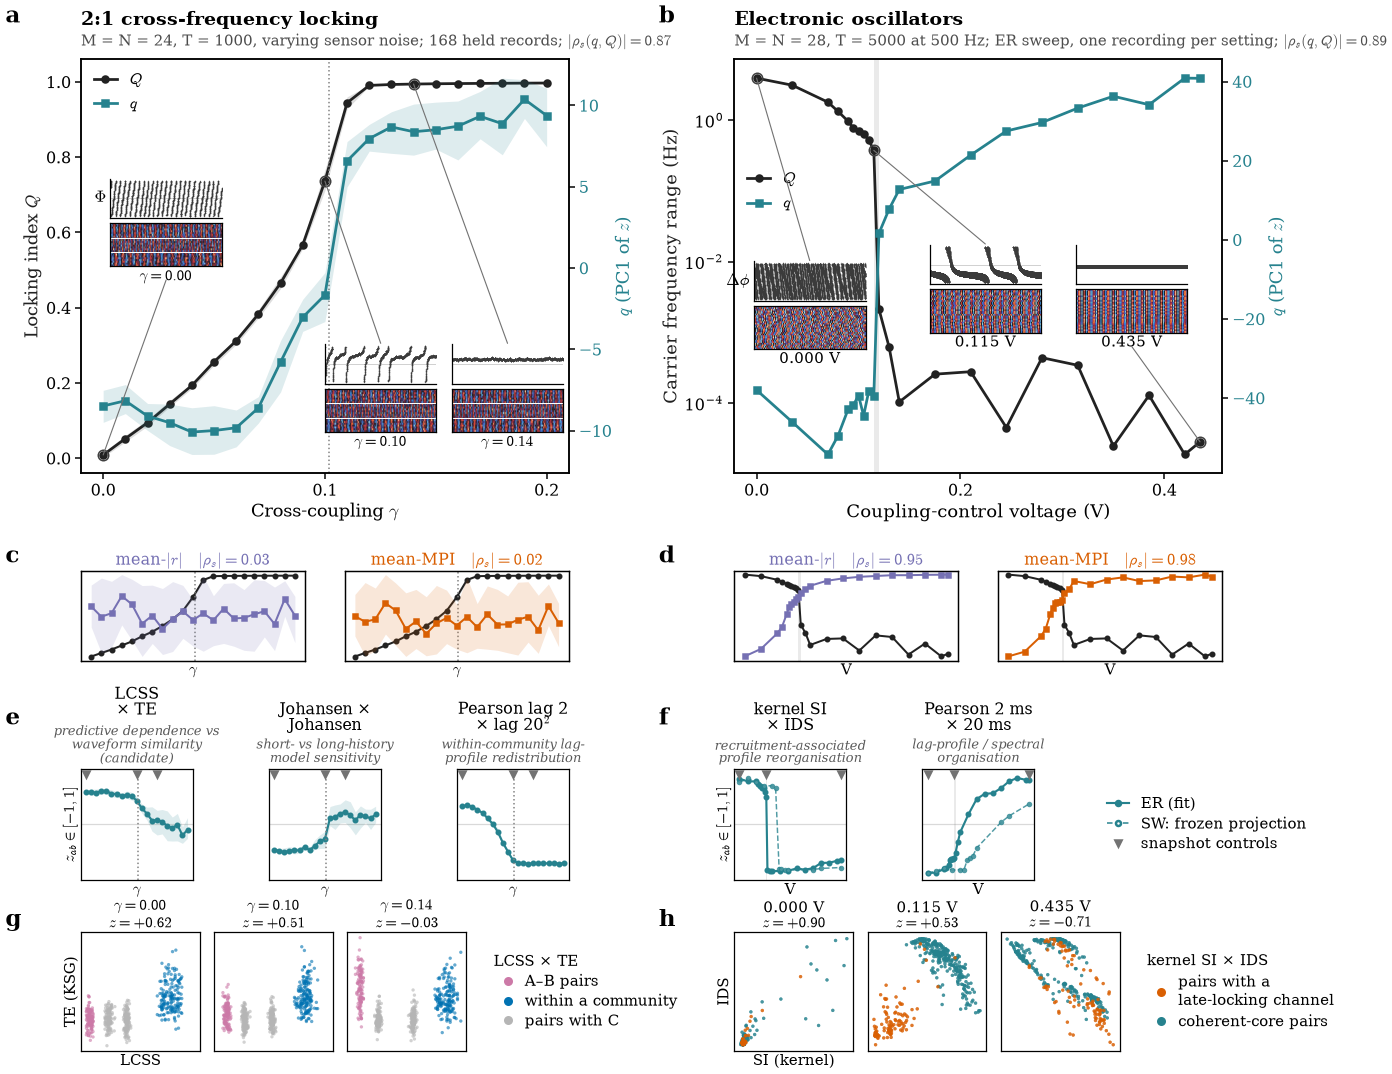

In [3]:
show(cf.save(cf.composite([locking, hardware], glyphs={'locking': 'wrapped', 'hardware': 'wrapped'}), 'composite-v1-wrapped'))

## Iteration 2: Lissajous (locking) and synchrony $R(t)$ (hardware)

The Lissajous is the most immediate portrait of 2:1 locking, but it uses the latent community mean fields rather than an observed channel. $R(t)$ summarises all 28 channels and hides which channels slip.

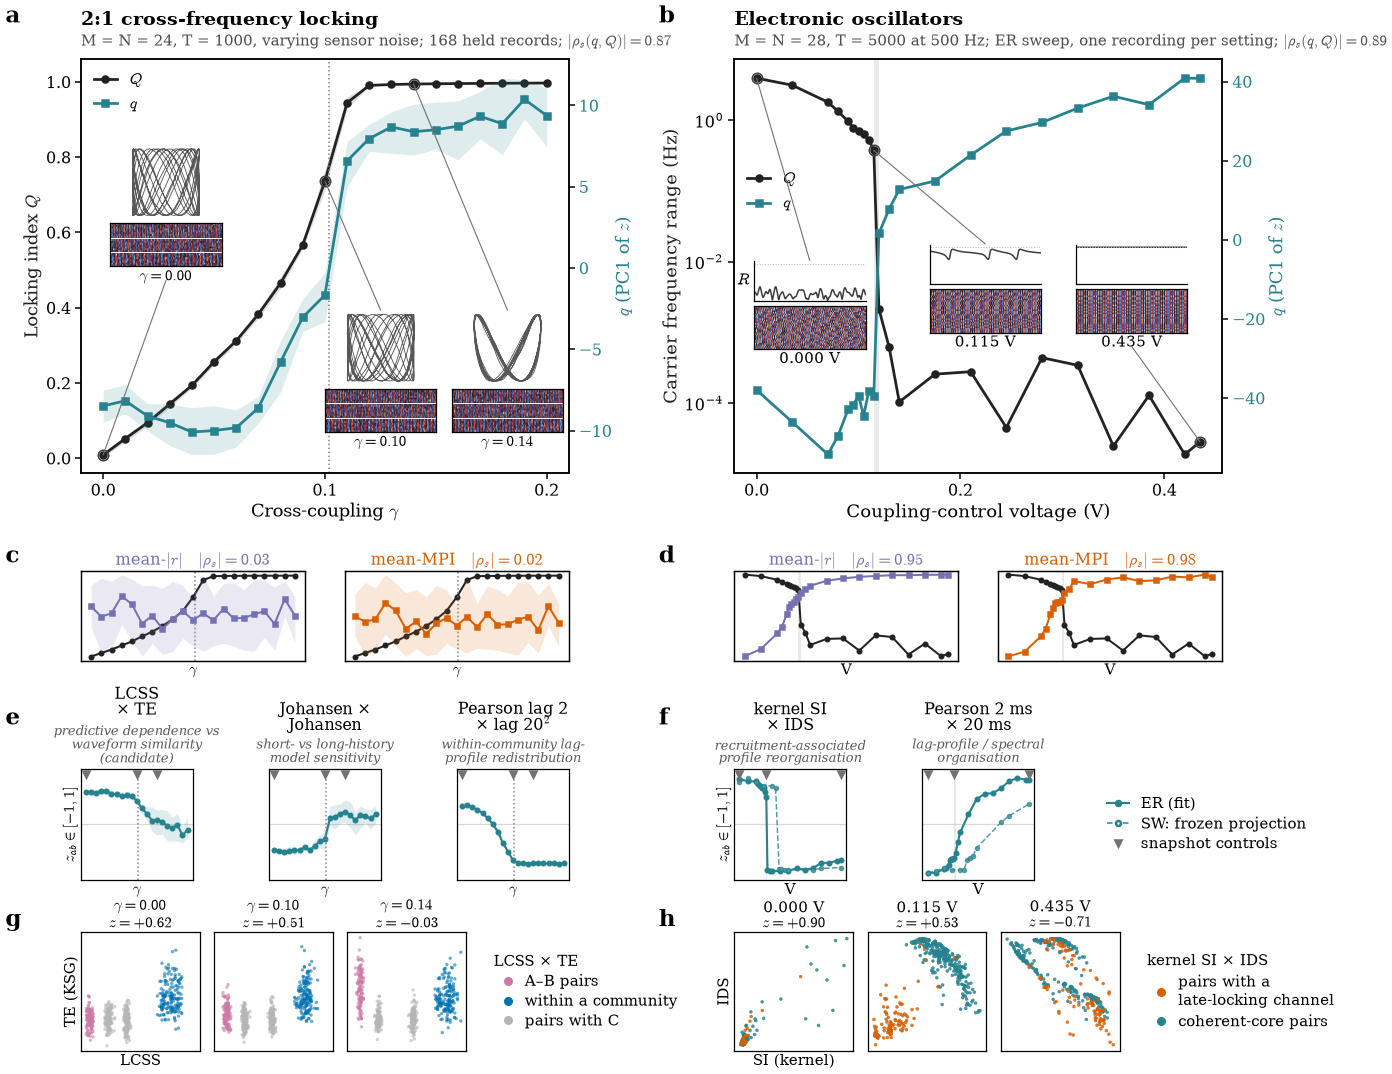

In [4]:
show(cf.save(cf.composite([locking, hardware], glyphs={'locking': 'lissajous', 'hardware': 'synchrony'}), 'composite-v2-lissajous-synchrony'))

## Iteration 3: spiral (locking) and phase raster (hardware)

Both are scale-free but denser. At 0.115 V the raster's top four rows show the late-locking channels' slips against a locked core.

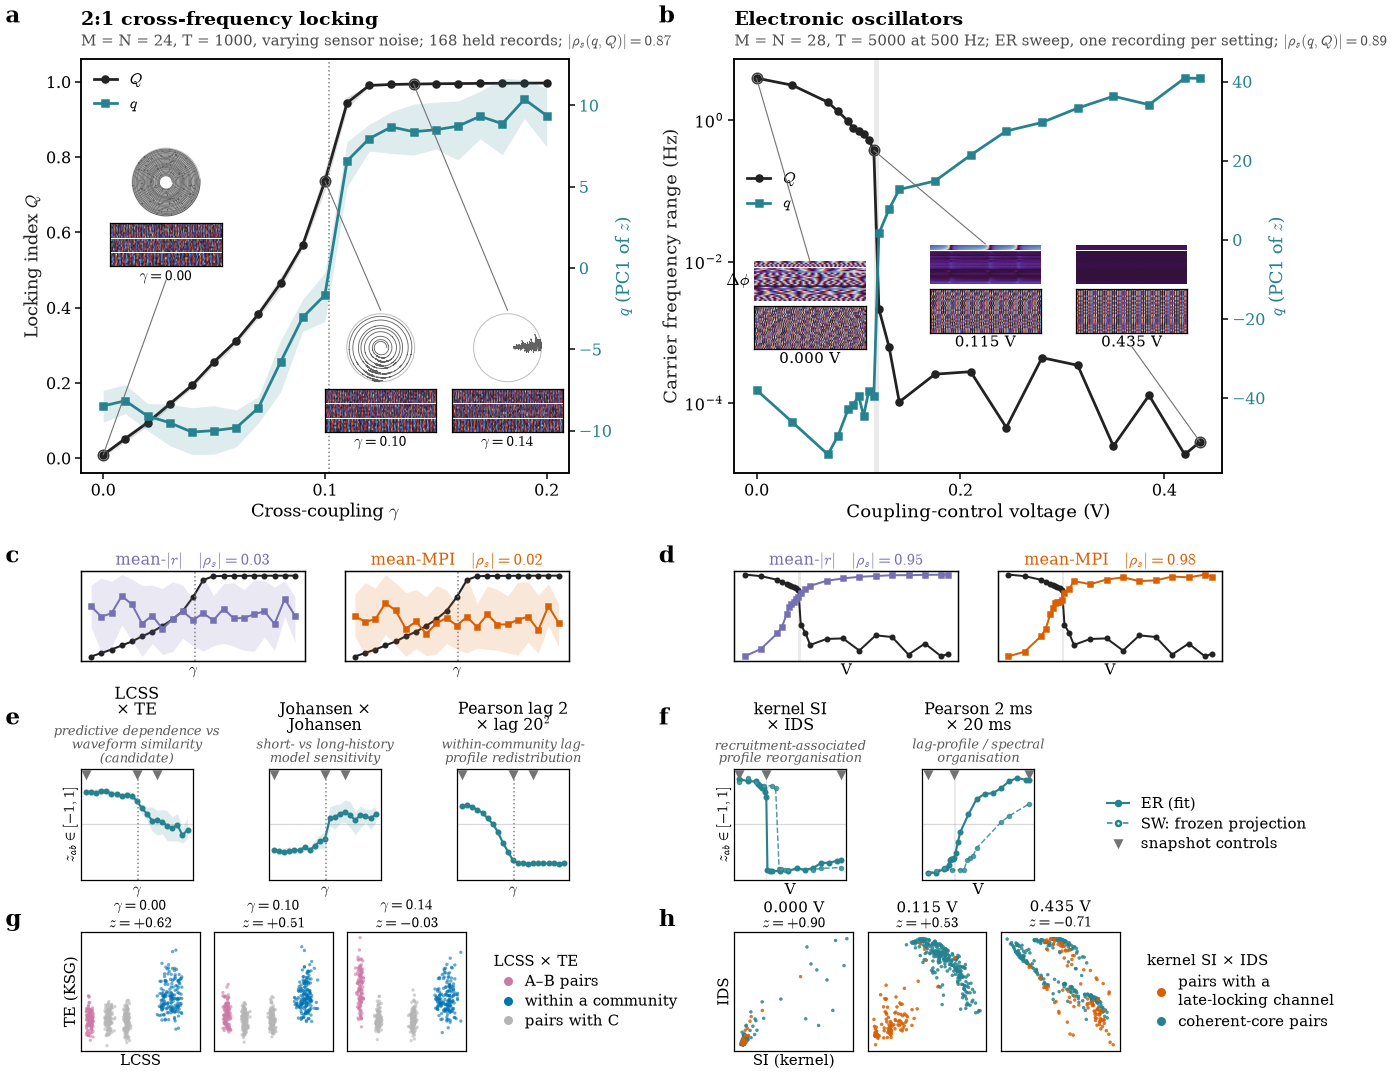

In [5]:
show(cf.save(cf.composite([locking, hardware], glyphs={'locking': 'spiral', 'hardware': 'raster'}), 'composite-v3-spiral-raster'))

## All glyph variants side by side

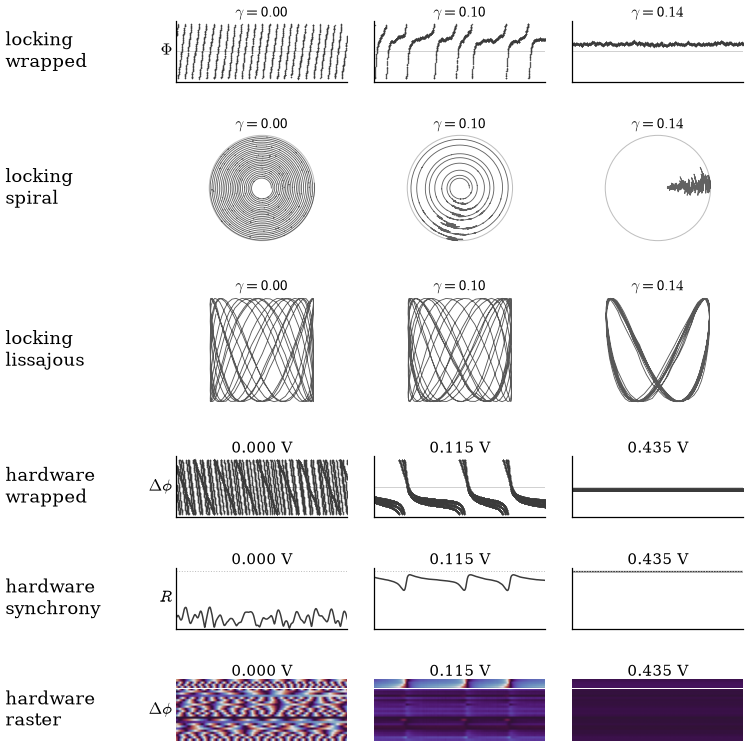

In [6]:
show(cf.save(cf.glyph_gallery([locking, hardware]), 'glyph-gallery'), width=520)

## Extended feature rows: two edge-plane rows per system

Second rows: Johansen max-eigen × trace (locking) and Pearson 2 ms × 20 ms (hardware). Hardware edge planes are scaled per panel because $z$ is scale-free and the 0 V profiles are near-degenerate; locking rows share limits.

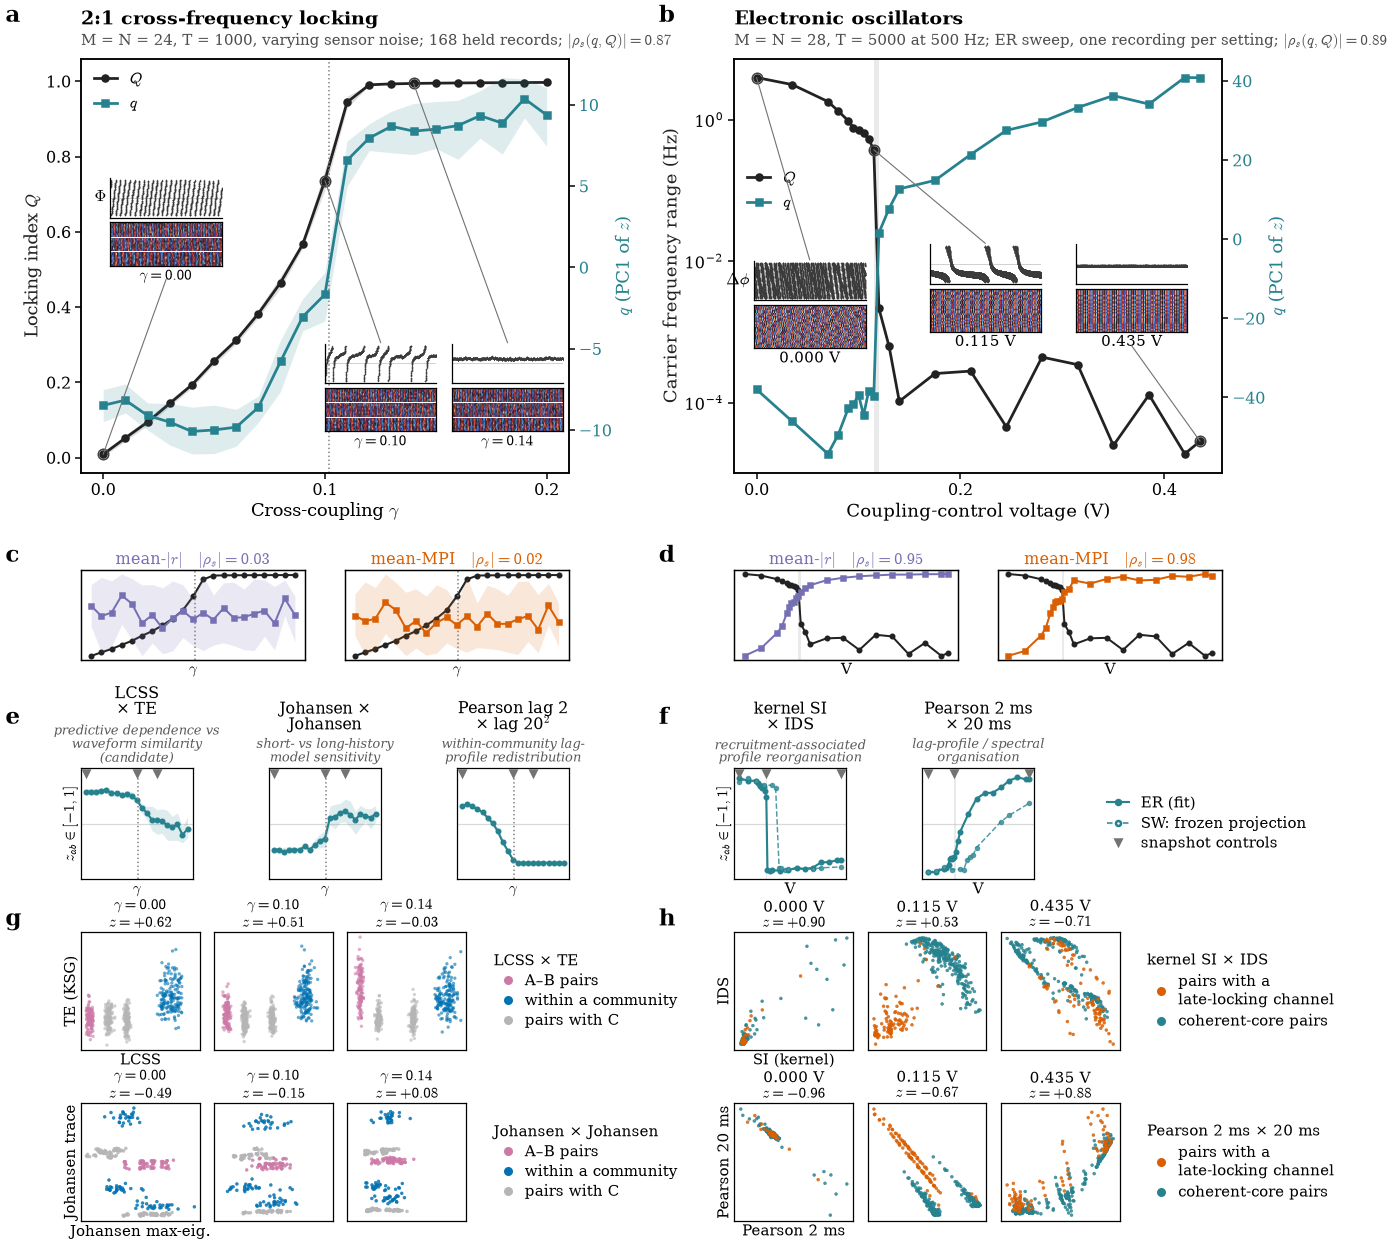

In [7]:
show(cf.save(cf.composite([locking, hardware], edge_rows={'locking': (0, 1), 'hardware': (0, 1)}), 'composite-v4-two-edge-rows'))

## Hardware: which physical quantity?

No universal order parameter is known for this apparatus. **Default:** the across-channel range of mean carrier frequency (log axis), whose collapse marks the cessation of phase slips at 23→24. **Alternatives:** mean carrier phase coherence $R_1$ (smooth and almost a monotone function of mean-$|r|$, rank correlation 1.00 on ER); the temporal SD of $R(t)$; the fraction of frequency-locked channels (needs a threshold). With $R_1$ the rank association of $q$ is similar, but $Q$ no longer shows the step that $q$ shows at slip cessation.

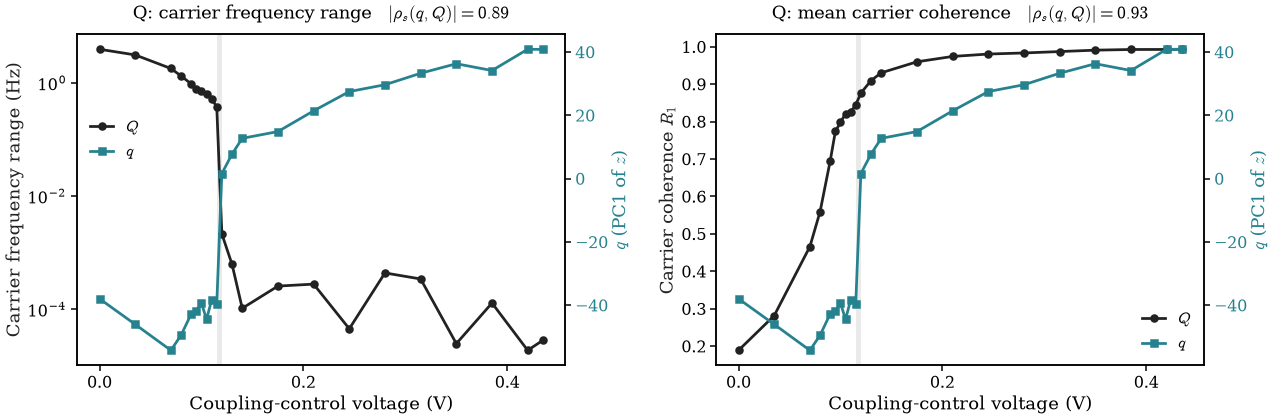

In [8]:
hardware_r1 = cf.load('hardware', Q_source='R1', Q_label='Carrier coherence $R_1$', Q_log=False, legend_loc='lower right')
show(cf.save(cf.compare_Q([hardware, hardware_r1], ['Q: carrier frequency range', 'Q: mean carrier coherence']), 'hardware-Q-alternatives'), width=800)

## Baselines: where simple statistics do as well

Locking (held records, $|\rho_s|$ with $Q$): $q$ .871, mean-$|r|$ .032, mean-MPI PC1 .020, as in the original analysis. Here the advantage is the ordering of variation under recording-specific noise, not information absent from the means; a supervised mean-vector readout reaches .900.

Hardware (ER settings ≤ 87): $q$ .892, mean-$|r|$ .950, mean-MPI PC1 .982; small-world .841 / .879 / .929. Rank association therefore does not favour $q$; this transition is strength-correlated. The descriptive difference is localisation. In ER, $q$ crosses 43% of its displayed range over the single slip-cessation interval 23→24 (log $Q$: 42%), compared with 4.5% for mean-$|r|$ and 8.9% for mean-MPI, whose largest changes come before locking. In small-world all three change most over 31→34 (52%, 29%, 37%), on a coarser grid. These shares depend on the adaptive control grid and are not a test.

In [9]:
from research.inference.benchmarks import hardware_baselines as hb
table = pd.read_csv(hb.OUT/'metrics.csv')
table.query("scope == 'settings ≤87'").round(3)

,topology,scope,n,readout,abs_rho_frequency_range,abs_rho_R1,locking_share,largest_step,largest_step_share,steepest_slope
0,ER,settings ≤87,22,Q: log frequency range,1.000,0.950,0.421,23→24,0.421,23→24
1,ER,settings ≤87,22,SPI–SPI PC1,0.892,0.932,0.432,23→24,0.432,23→24
2,ER,settings ≤87,22,mean-|r|,0.950,1.000,0.045,7→14,0.191,18→19
3,ER,settings ≤87,22,mean-MPI PC1,0.982,0.980,0.089,7→14,0.190,16→18
8,SW,settings ≤87,13,Q: log frequency range,1.000,0.879,0.660,31→34,0.660,31→34
9,SW,settings ≤87,13,SPI–SPI PC1,0.841,0.852,0.518,31→34,0.518,31→34
10,SW,settings ≤87,13,mean-|r|,0.879,0.956,0.292,7→14,0.297,31→34
11,SW,settings ≤87,13,mean-MPI PC1,0.929,0.956,0.369,31→34,0.369,31→34


## Registry example: CML2D

The registry is not specific to the two systems above. The collective period-two CML (confirmation bank) loads by name with its own loader, passes the same ordered-contract replay and renders with the shared code. Its baselines are stronger than $q$ (.97 versus .88), as recorded in the benchmark context. Kuramoto and Stuart–Landau need only a loader returning the same `SystemData` fields.

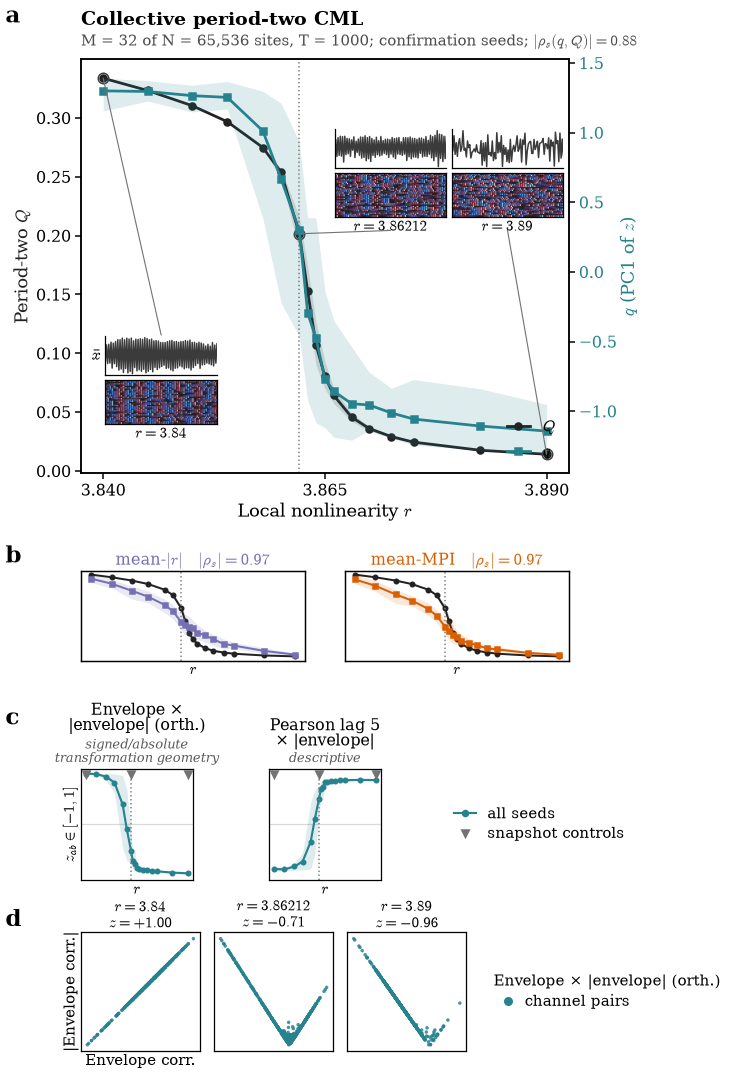

In [10]:
cml = cf.load('cml2d')
show(cf.save(cf.composite([cml]), 'registry-example-cml2d'), width=520)

## Export individual panels

In [11]:
written = {d.spec.name: cf.export_panels(d) for d in (locking, hardware)}
receipt = cf.receipt([locking, hardware])
print({k: len(v) for k, v in written.items()}, 'panels (each as SVG, PDF and PNG) under', cf.OUT/'panels')
print('provenance:', receipt.relative_to(ROOT))

{'locking': 32, 'hardware': 28} panels (each as SVG, PDF and PNG) under /Users/wedi0306/Code/mts-spi-study-cluster/results/order-parameter-inference/composites-261021/panels
provenance: results/order-parameter-inference/composites-261021/provenance.json


## Open choices

1. **Glyphs.** Locking: wrapped $\Phi$ (default), Lissajous or spiral. Hardware: wrapped late-channel phase (default), $R(t)$ or phase raster.
2. **Hardware $Q$.** Frequency range (default), $R_1$, the SD of $R(t)$, or a locked-channel fraction.
3. **Hardware display range.** Settings ≤ 87 (0–0.435 V, as in the three-systems notebook) or the full 0–3.5 V sweep. Over the full sweep $q$ is non-monotone: it dips at 0.875 V while the frequency range stays at its floor, and the calibrated spectral explanation fails at settings 175–437.
4. **Locking post-transition snapshot.** $\gamma=.14$ (local MPI) or $\gamma=.20$, which needs one held MPI fetched from Gadi for the edge planes.
5. **Small-world.** Currently a dashed frozen projection in the feature rows only. It could also enter the headline as a second dashed $Q$/$q$ pair.
6. **Feature rows.** Locking shows three pairs and one edge row (LCSS × TE); the Johansen and lag-profile pairs could replace or join it. Hardware shows SI × IDS and Pearson 2 ms × 20 ms.